In [1]:
import numpy as np 
import pandas as pa
import seaborn as se
import matplotlib.pyplot as plt
from keras.layers import Dense , Flatten , Normalization , Input , Resizing , Conv2D , MaxPooling2D , Dropout
from keras.models import Sequential , load_model
from keras.callbacks import EarlyStopping
from sklearn.metrics import r2_score
import tensorflow as tf 
from IPython import display
import pathlib
%matplotlib widget

In [2]:
data_dir = pathlib.Path('data/')

In [3]:
tf.io.gfile.listdir(str(data_dir))

['down', 'go', 'left', 'no', 'right', 'stop', 'up', 'yes']

In [4]:
commands = np.array(tf.io.gfile.listdir(str(data_dir)))
commands = commands[(commands != 'README.md') & (commands != '.DS_Store') & (commands != 'voicedataset.zip')]
print('Commands Available:', commands)

Commands Available: ['down' 'go' 'left' 'no' 'right' 'stop' 'up' 'yes']


In [5]:
X_train , X_test = tf.keras.utils.audio_dataset_from_directory(
    directory = data_dir,
    batch_size = 64,
    validation_split = 0.2,
    seed = 0,
    output_sequence_length = 16000,
    subset = 'both'
)

label_names = np.array(X_train.class_names)
print()
print(label_names) 

Found 8000 files belonging to 8 classes.
Using 6400 files for training.
Using 1600 files for validation.

['down' 'go' 'left' 'no' 'right' 'stop' 'up' 'yes']


In [6]:
def sequnz(audio,label) :
    audio = tf.squeeze(audio,axis=-1)
    return audio , label

X_train = X_train.map(sequnz,tf.data.AUTOTUNE)
X_test = X_test.map(sequnz,tf.data.AUTOTUNE)

In [7]:
val = X_test 
X_test = X_test.shard(num_shards=2,index=0)
val = X_test.shard(num_shards=2,index=1)

In [8]:
for x , y in X_train.take(1) :
    print(x)
    print()
    print(label_names[y])
    print(y)

tf.Tensor(
[[ 1.4648438e-03  4.5776367e-03  2.9602051e-03 ...  3.2653809e-03
   2.5634766e-03  3.6926270e-03]
 [ 6.9885254e-03  5.8898926e-03  6.7749023e-03 ...  9.4604492e-03
   8.2092285e-03  8.0566406e-03]
 [ 0.0000000e+00  8.5449219e-04 -3.9672852e-04 ...  3.7231445e-03
  -1.2817383e-03 -3.2043457e-03]
 ...
 [-1.3122559e-03 -1.6174316e-03 -2.5329590e-03 ... -2.9602051e-03
  -2.7770996e-03 -2.4719238e-03]
 [ 6.1035156e-05  3.0517578e-05 -3.0517578e-05 ... -1.5258789e-04
   3.0517578e-05  2.1362305e-04]
 [-3.0517578e-04 -2.2277832e-03 -2.8686523e-03 ... -3.0517578e-05
   2.7465820e-04  1.0375977e-03]], shape=(64, 16000), dtype=float32)

['down' 'go' 'right' 'no' 'down' 'left' 'yes' 'go' 'stop' 'go' 'left' 'up'
 'down' 'left' 'left' 'down' 'down' 'down' 'go' 'no' 'yes' 'right' 'up'
 'down' 'down' 'no' 'up' 'up' 'go' 'yes' 'yes' 'no' 'stop' 'stop' 'up'
 'go' 'right' 'stop' 'left' 'down' 'no' 'down' 'down' 'up' 'no' 'down'
 'down' 'go' 'stop' 'yes' 'no' 'stop' 'up' 'stop' 'right' 'go' '

In [9]:
for example_audio , example_label in X_train.take(1) :
    print(example_audio.shape)
    print(example_label.shape)

(64, 16000)
(64,)


In [10]:
display.display(display.Audio(example_audio[6],rate=16000))

audio 0


audio 1


audio 2


audio 3


audio 4


audio 5


audio 6


audio 7


audio 8


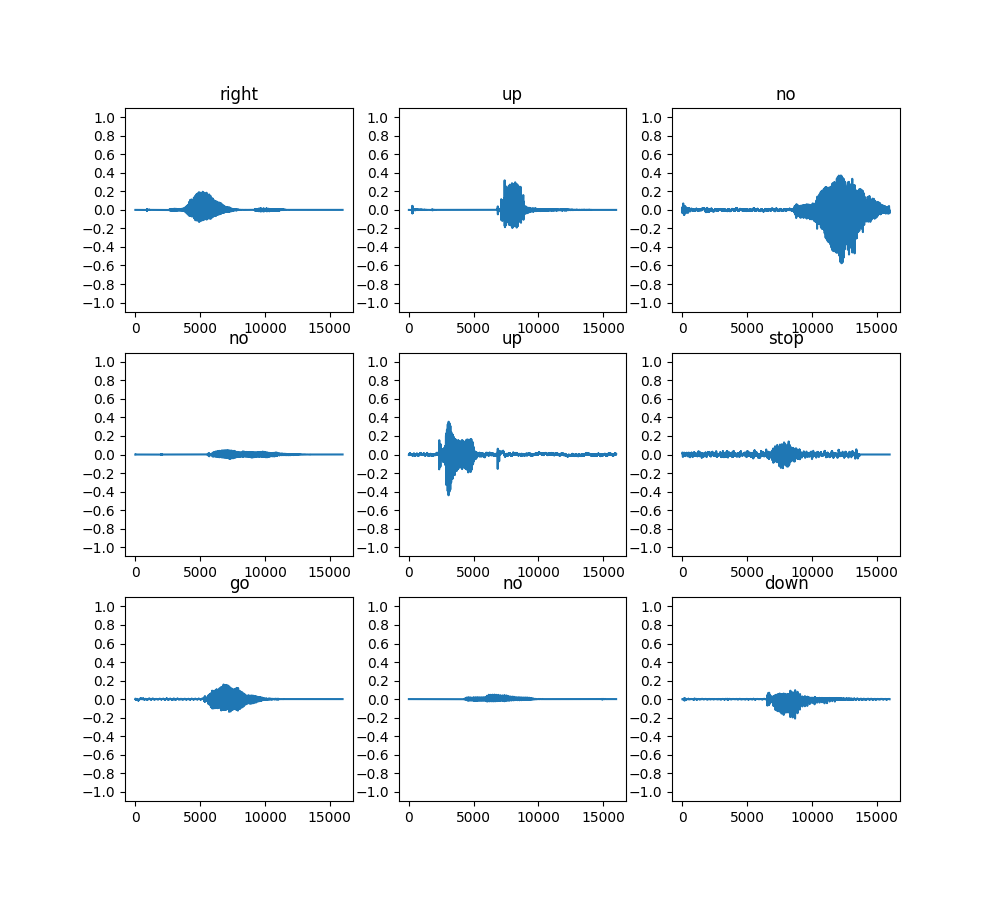

In [11]:
plt.close()
plt.figure(figsize=(10,9))
row = 3 
cole = 3 
n = row * cole 
for i in range(n) :
    plt.subplot(row,cole,i+1)
    plt.plot(example_audio[i])
    plt.title(label_names[example_label[i]])
    plt.yticks(np.arange(-1.2,1.2,0.2))
    plt.ylim([-1.1,1.1])
    print('audio',i)
    display.display(display.Audio(example_audio[i],rate=16000))
plt.show()    

In [12]:
def specgram(wavfrom) :
    specgramer = tf.signal.stft(wavfrom,frame_length=124,frame_step=129)
    specgramer = tf.abs(specgramer)
    specgramer = specgramer[...,tf.newaxis]
    return specgramer    


In [13]:
for x in range(3) :
    label = label_names[example_label[x]]
    wavfrom = example_audio[x]
    spec = specgram(wavfrom=wavfrom)

    print('label',label)
    print('wav.shape',wavfrom.shape)
    print('specgram.shape',spec.shape)
    print('audio is :')
    display.display(display.Audio(example_audio[x],rate=16000))


label right
wav.shape (16000,)
specgram.shape (124, 65, 1)
audio is :


label up
wav.shape (16000,)
specgram.shape (124, 65, 1)
audio is :


label no
wav.shape (16000,)
specgram.shape (124, 65, 1)
audio is :


In [14]:
def plot_specgram(specgramm,ax) :
    if len(specgramm.shape) > 2 :
        assert len(specgramm.shape) == 3
        specgramm = np.squeeze(specgramm,axis=-1)
    log_spec = np.log(specgramm.T+np.finfo(float).eps)
    height = log_spec.shape[0]
    width = log_spec.shape[1]
    X = np.linspace(1,np.size(specgramm),num=width,dtype=int)
    Y = range(height)
    ax.pcolormesh(X,Y,log_spec)    

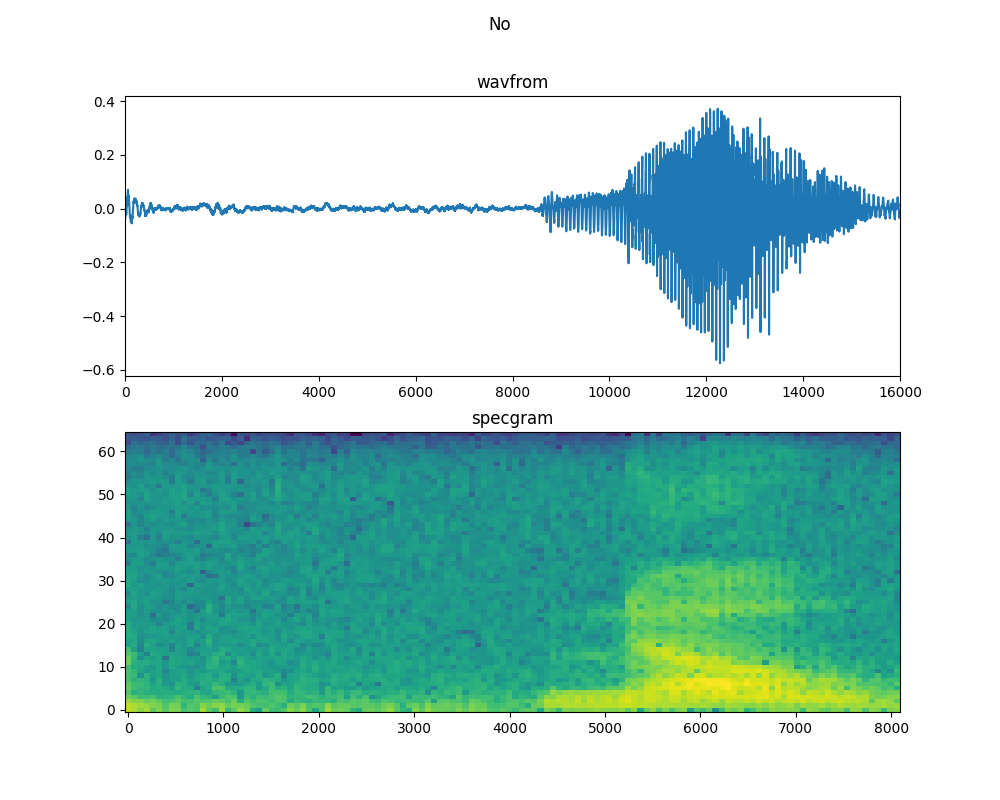

In [15]:
plt.close()
fig , axes = plt.subplots(2,figsize=(10,8))
timescal = np.arange(wavfrom.shape[0])
axes[0].plot(timescal,wavfrom.numpy())
axes[0].set_title('wavfrom')
axes[0].set_xlim([0,16000])

plot_specgram(specgramm=spec.numpy(),ax=axes[1])
axes[1].set_title('specgram')

plt.suptitle(label.title())
plt.show()
display.display(display.Audio(wavfrom,rate=16000))


In [16]:
def make_spec_ds(ds) :
    return ds.map(
        map_func=lambda audio , label : (specgram(audio), label),
        num_parallel_calls=tf.data.AUTOTUNE
    )

In [17]:
train_spectgram_ds = make_spec_ds(X_train)
val_spectgram_ds = make_spec_ds(val)
test_spectgram_ds = make_spec_ds(X_test)

In [18]:
for example_spec_audio , example_spec_label in train_spectgram_ds.take(1) :
    print(example_spec_audio)
    print()
    print(label_names[example_spec_label])
    print(example_spec_label)

tf.Tensor(
[[[[2.67143585e-02]
   [6.39904067e-02]
   [1.29002750e-01]
   ...
   [1.33441456e-04]
   [7.16032373e-05]
   [2.82563269e-05]]

  [[2.42747068e-02]
   [1.46701589e-01]
   [2.96379060e-01]
   ...
   [1.68239640e-04]
   [5.27150551e-05]
   [3.55988741e-05]]

  [[1.00747049e-02]
   [1.73152760e-01]
   [3.72997373e-01]
   ...
   [2.71207555e-05]
   [6.64467661e-05]
   [1.59516931e-05]]

  ...

  [[8.56447071e-02]
   [6.76816553e-02]
   [1.51478583e-02]
   ...
   [7.82483257e-05]
   [3.34298638e-05]
   [6.89178705e-07]]

  [[8.44635218e-02]
   [7.58630559e-02]
   [2.41803173e-02]
   ...
   [1.06083680e-04]
   [6.89045992e-05]
   [3.08305025e-05]]

  [[1.14761971e-01]
   [7.64437988e-02]
   [2.05034278e-02]
   ...
   [7.67175225e-05]
   [4.64971454e-05]
   [2.16737390e-05]]]


 [[[3.12263914e-03]
   [3.30555672e-03]
   [2.61723087e-03]
   ...
   [6.71330563e-05]
   [3.14218087e-05]
   [4.42645978e-05]]

  [[3.82650690e-03]
   [3.34833493e-03]
   [2.09877989e-03]
   ...
   [7.2471

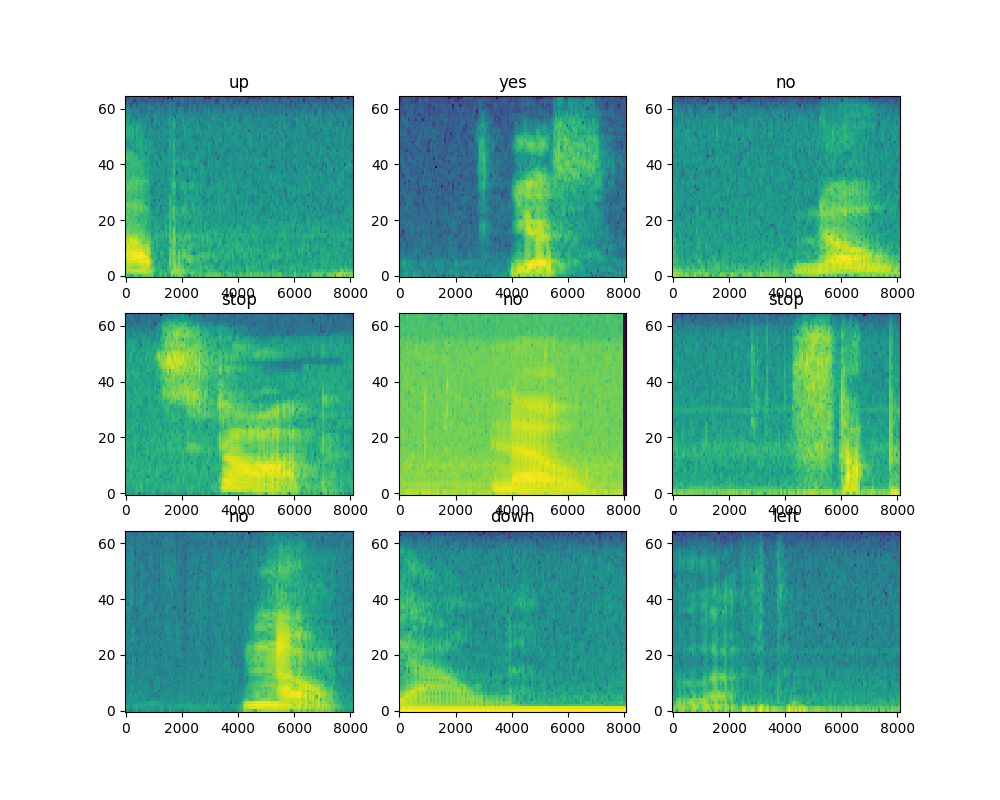

In [19]:
row = 3 
cloe = 3
n = row * cloe
fig , axes = plt.subplots(row,cloe,figsize=(10,8))

for i in range(n) :
    r = i // cloe
    c = i % cloe
    ax = axes[r][c]
    plot_specgram(example_spec_audio[i].numpy(),ax)
    ax.set_title(label_names[example_spec_label[i].numpy()])
plt.show()    

In [20]:
train_spectgram_ds = train_spectgram_ds.cache().shuffle(10000).prefetch(tf.data.AUTOTUNE)
val_spectgram_ds = val_spectgram_ds.cache().prefetch(tf.data.AUTOTUNE)
test_spectgram_ds = test_spectgram_ds.cache().prefetch(tf.data.AUTOTUNE)

In [21]:
example_spec_audio.shape

TensorShape([64, 124, 65, 1])

In [22]:
input_shape = example_spec_audio.shape[1:] 
num_label = len(label_names)

norm_layer = Normalization()
norm_layer.adapt(data=train_spectgram_ds.map(map_func=lambda spec , label : spec))


model = Sequential([
    Input(shape=input_shape),
    Resizing(36,36),
    norm_layer,
    Conv2D(64,3,activation='relu'),
    Conv2D(128,3,activation='relu'),
    MaxPooling2D(),
    Dropout(0.5),
    Flatten(),
    Dense(256,activation='relu'),
    Dropout(0.75),
    Dense(8),
])

model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 resizing (Resizing)         (None, 36, 36, 1)         0         
                                                                 
 normalization (Normalizatio  (None, 36, 36, 1)        3         
 n)                                                              
                                                                 
 conv2d (Conv2D)             (None, 34, 34, 64)        640       
                                                                 
 conv2d_1 (Conv2D)           (None, 32, 32, 128)       73856     
                                                                 
 max_pooling2d (MaxPooling2D  (None, 16, 16, 128)      0         
 )                                                               
                                                                 
 dropout (Dropout)           (None, 16, 16, 128)       0

In [23]:
model.compile(loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),optimizer='adam',metrics=['accuracy'])

In [24]:
erly = EarlyStopping(
    monitor='val_accuracy',
    patience=5,
    mode='max',
    restore_best_weights=True
)

In [25]:
model.fit(train_spectgram_ds,validation_data=val_spectgram_ds,callbacks=[erly],epochs=30)

Epoch 1/30
100/100 [==============================] - 29s 287ms/step - loss: 1.8064 - accuracy: 0.3411 - val_loss: 1.2861 - val_accuracy: 0.6536
Epoch 2/30
100/100 [==============================] - 26s 264ms/step - loss: 1.2378 - accuracy: 0.5738 - val_loss: 0.9730 - val_accuracy: 0.6771
Epoch 3/30
100/100 [==============================] - 26s 260ms/step - loss: 0.9955 - accuracy: 0.6600 - val_loss: 0.7400 - val_accuracy: 0.7604
Epoch 4/30
100/100 [==============================] - 26s 259ms/step - loss: 0.8223 - accuracy: 0.7148 - val_loss: 0.6202 - val_accuracy: 0.7995
Epoch 5/30
100/100 [==============================] - 26s 259ms/step - loss: 0.7171 - accuracy: 0.7489 - val_loss: 0.5991 - val_accuracy: 0.8333
Epoch 6/30
100/100 [==============================] - 26s 263ms/step - loss: 0.6517 - accuracy: 0.7758 - val_loss: 0.5166 - val_accuracy: 0.8438
Epoch 7/30
100/100 [==============================] - 28s 278ms/step - loss: 0.5917 - accuracy: 0.7930 - val_loss: 0.4861 - val_ac

In [26]:
model.evaluate(test_spectgram_ds,return_dict=True)

13/13 [==============================] - 1s 71ms/step - loss: 0.4020 - accuracy: 0.8726


{'loss': 0.4020029604434967, 'accuracy': 0.8725961446762085}

In [27]:
out_robot = model.predict(test_spectgram_ds)

13/13 [==============================] - 1s 47ms/step


In [28]:
out_robot = tf.argmax(out_robot,axis=1)


In [29]:
y_true = tf.concat(list(test_spectgram_ds.map(lambda s,lab : lab)),axis=0)

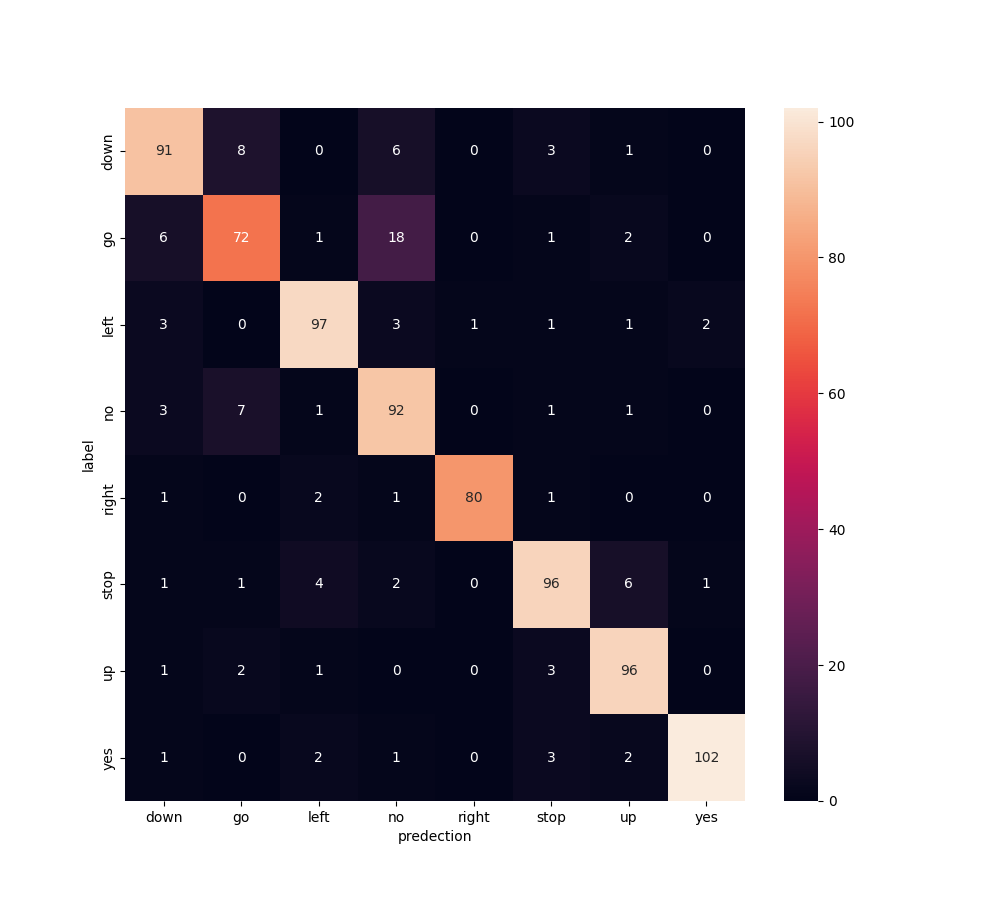

In [30]:
confusion_mtx = tf.math.confusion_matrix(y_true,out_robot)
plt.figure(figsize=(10,9))
se.heatmap(confusion_mtx,xticklabels=label_names,yticklabels=label_names,annot=True,fmt='g')
plt.xlabel('predection')
plt.ylabel('label')
plt.show()
